# Credit Card Default Prediction Using Machine Learning

## Problem Statement

The objective of this project is to predict whether a credit card customer will default on their payment using machine learning classification models.

The target variable is Y:

- 0 → No Default
- 1 → Default

## Dataset Description

The dataset contains information about credit card customers, including demographic details, credit limit, repayment status, bill amounts, and payment amounts.

The target variable Y represents whether the customer defaulted on the next month's payment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## Data Loading

The credit card default dataset is loaded using Pandas for further analysis and preprocessing.

In [2]:
df = pd.read_csv("default of credit card clients.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (30001, 25)


## Initial Dataset Inspection

The dataset is inspected to understand its structure, feature types, missing values, duplicate records, and target variable distribution.

In [3]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:


,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0



Column names:
['Unnamed: 0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']

Data types:
Unnamed: 0    str
X1            str
X2            str
X3            str
X4            str
X5            str
X6            str
X7            str
X8            str
X9            str
X10           str
X11           str
X12           str
X13           str
X14           str
X15           str
X16           str
X17           str
X18           str
X19           str
X20           str
X21           str
X22           str
X23           str
Y             str
dtype: object

Missing values:
Unnamed: 0    0
X1            0
X2            0
X3            0
X4            0
X5            0
X6            0
X7            0
X8            0
X9            0
X10           0
X11           0
X12           0
X13           0
X14           0
X15           0
X16           0
X17           0
X18           0
X19           0

### Data Cleaning

The dataset contains an additional header row within the data. This row is removed and the remaining values are converted to numeric format. Duplicate rows are checked and removed to avoid repeated observations affecting model training and evaluation.


In [4]:
# Remove the extra header row
df = df.iloc[1:].copy()
df = df.drop(columns=["Unnamed: 0"])

# Convert all columns to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Cleaned dataset shape: (30000, 24)

Total missing values: 0
Duplicate rows: 35
Shape after removing duplicates: (29965, 24)


## Target Variable Distribution

The target variable Y represents credit card payment default. Class 0 represents no default, while class 1 represents default.

Target distribution:
Y
0    23335
1     6630
Name: count, dtype: int64


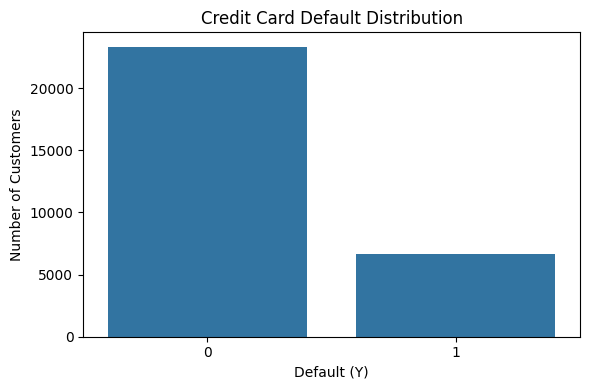

In [5]:
print("Target distribution:")
print(df["Y"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Y")

plt.title("Credit Card Default Distribution")
plt.xlabel("Default (Y)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Observation

The target variable contains two classes, 0 and 1. The distribution shows that the non-default class contains more customers than the default class, indicating class imbalance in the dataset.

## Descriptive Statistics

Descriptive statistics are used to understand the central tendency, spread, and range of the numerical features.

In [6]:
display(df.describe())

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
count,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,...,29965.000000,29965.000000,29965.000000,29965.000000,2.996500e+04,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000
mean,167442.005006,1.603738,1.853629,1.551877,35.487969,-0.016753,-0.131854,-0.164392,-0.218922,-0.264509,...,43313.329885,40358.334390,38917.012281,5670.099316,5.927983e+03,5231.688837,4831.617454,4804.897047,5221.498014,0.221258
std,129760.135222,0.489128,0.790411,0.521997,9.219459,1.123492,1.196322,1.195878,1.168175,1.132220,...,64353.514373,60817.130623,59574.147742,16571.849467,2.305346e+04,17616.361124,15674.464538,15286.372298,17786.976864,0.415101
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2360.000000,1787.000000,1262.000000,1000.000000,8.500000e+02,390.000000,300.000000,261.000000,131.000000,0.000000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,19081.000000,18130.000000,17124.000000,2102.000000,2.010000e+03,1804.000000,1500.000000,1500.000000,1500.000000,0.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,54601.000000,50247.000000,49252.000000,5008.000000,5.000000e+03,4512.000000,4016.000000,4042.000000,4000.000000,0.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.000000,621000.000000,426529.000000,528666.000000,1.000000


## Feature Distribution Analysis

Distribution plots are used to examine the spread and shape of the features in the dataset.

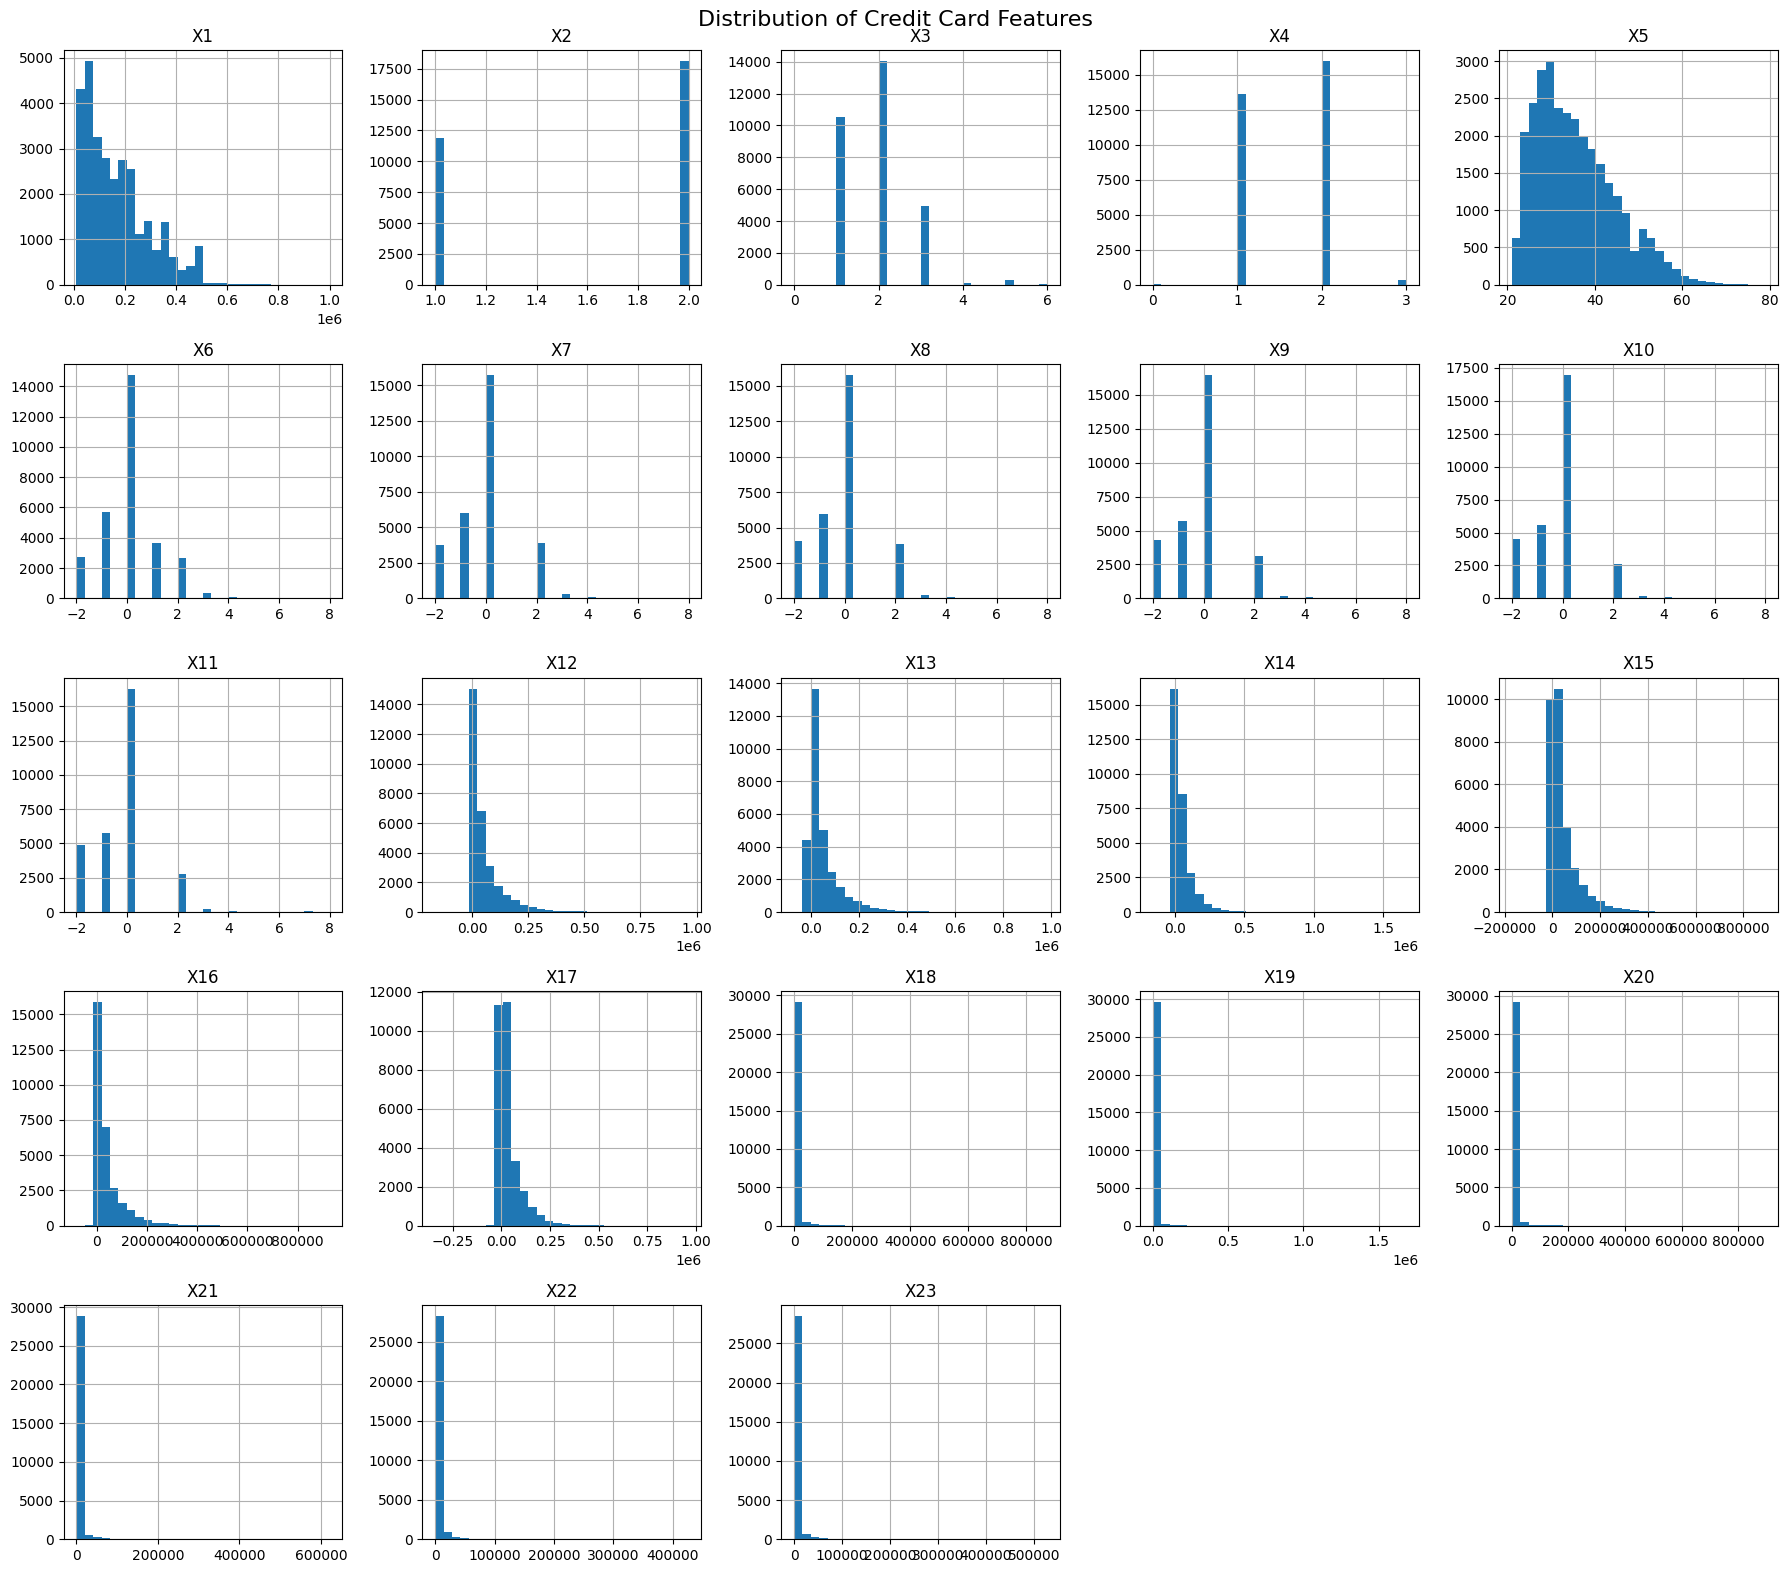

In [7]:
features = df.drop(columns=["Y"]).columns

df[features].hist(
    figsize=(18, 16),
    bins=30
)

plt.suptitle("Distribution of Credit Card Features", fontsize=16)
plt.tight_layout()
plt.show()

### Observation

The feature distributions have different ranges and shapes. Several financial variables show skewed distributions and extreme values, which require further outlier analysis before model training.

## Correlation Analysis

A correlation heatmap is used to examine relationships between numerical features.

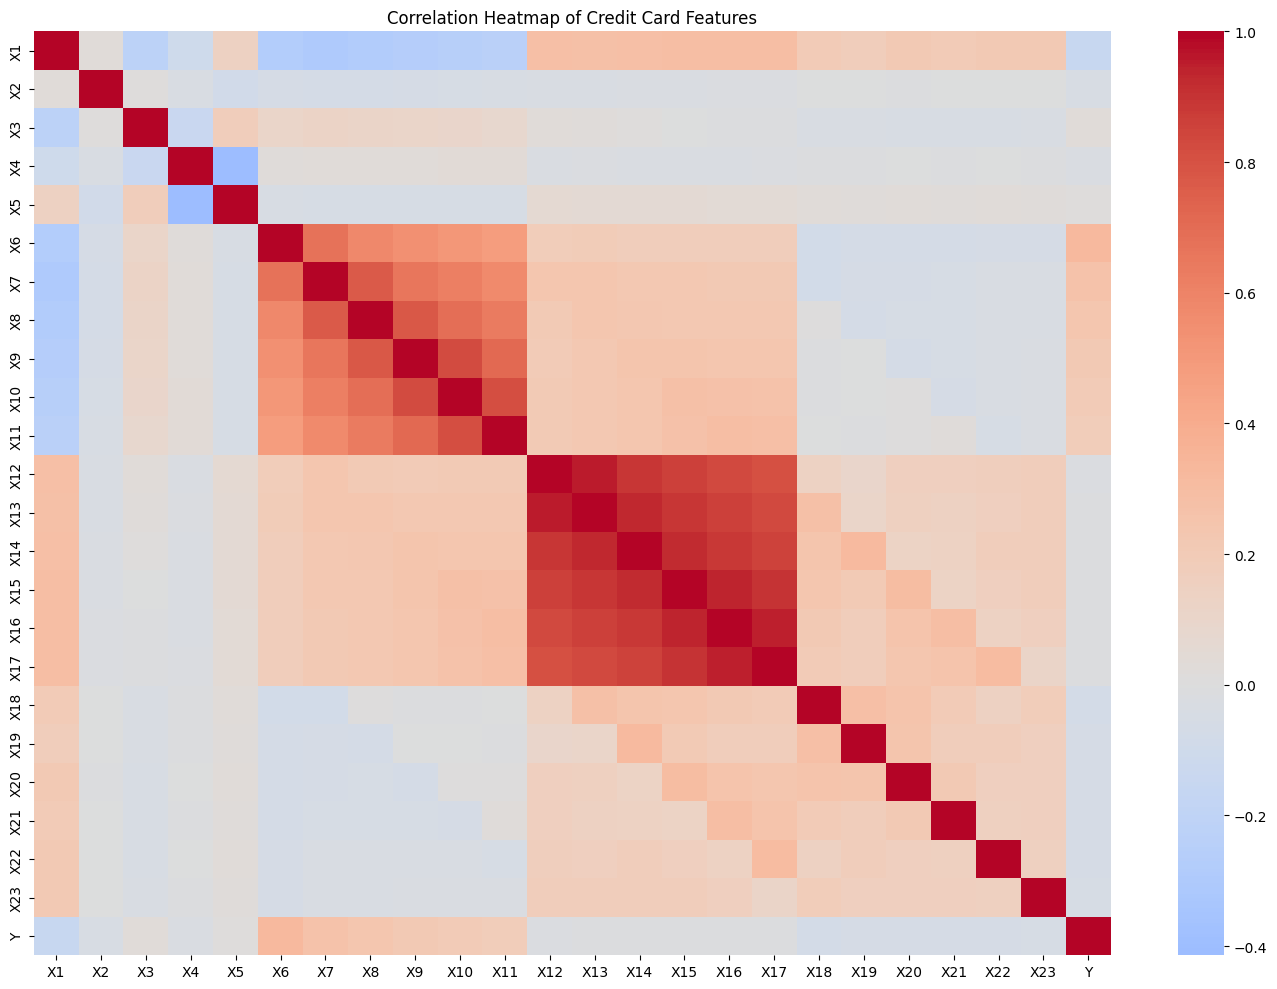

In [8]:
plt.figure(figsize=(14, 10))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Credit Card Features")
plt.tight_layout()
plt.show()

### Observation

The heatmap shows relationships among the numerical variables. The bill amount and payment amount features show relationships across different months because they represent related financial behaviour.

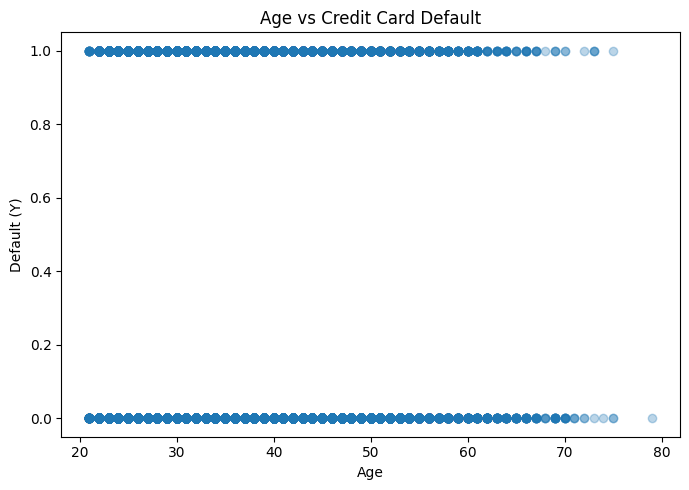

In [9]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df["X5"],
    df["Y"],
    alpha=0.3
)

plt.title("Age vs Credit Card Default")
plt.xlabel("Age")
plt.ylabel("Default (Y)")

plt.tight_layout()
plt.show()

### Observation

The plot shows considerable overlap between the default and non-default classes across different ages, indicating that age alone does not clearly separate the two classes.

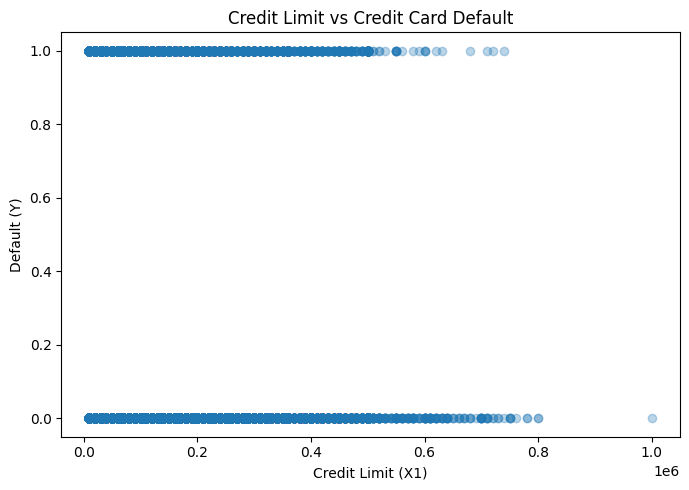

In [10]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df["X1"],
    df["Y"],
    alpha=0.3
)

plt.title("Credit Limit vs Credit Card Default")
plt.xlabel("Credit Limit (X1)")
plt.ylabel("Default (Y)")

plt.tight_layout()
plt.show()

### Observation

The plot shows overlap between default and non-default customers across different credit limits, indicating that credit limit alone is not sufficient to distinguish the target classes.

## Outlier Analysis

Outliers are checked in continuous numerical features using the Interquartile Range (IQR) method.

In [11]:
continuous_features = [
    "X1", "X5",
    "X12", "X13", "X14", "X15", "X16", "X17",
    "X18", "X19", "X20", "X21", "X22", "X23"
]

outlier_counts = {}

for col in continuous_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_counts[col] = (
        (df[col] < lower) | (df[col] > upper)
    ).sum()

print("Number of outliers in each feature:")
print(pd.Series(outlier_counts))

Number of outliers in each feature:
X1      167
X5      272
X12    2386
X13    2390
X14    2469
X15    2616
X16    2724
X17    2688
X18    2742
X19    2723
X20    2596
X21    2993
X22    2944
X23    2960
dtype: int64


## Feature Engineering

Two aggregate features are created to summarize the customer's billing and payment behaviour across the six available months.

In [12]:
bill_features = [
    "X12", "X13", "X14",
    "X15", "X16", "X17"
]

payment_features = [
    "X18", "X19", "X20",
    "X21", "X22", "X23"
]

df["Avg_Bill_Amount"] = df[bill_features].mean(axis=1)

df["Avg_Payment_Amount"] = df[payment_features].mean(axis=1)

print("New features created successfully!")

display(
    df[
        ["Avg_Bill_Amount", "Avg_Payment_Amount"]
    ].head()
)

New features created successfully!


,Avg_Bill_Amount,Avg_Payment_Amount
0,1284.000000,114.833333
1,2846.166667,833.333333
2,16942.166667,1836.333333
3,38555.666667,1398.000000
4,18223.166667,9841.500000


### Feature Engineering Justification

Avg_Bill_Amount represents the average bill amount across six months, while Avg_Payment_Amount represents the average payment amount across six months.

These features summarize the customer's overall billing and payment behaviour and may provide useful information for predicting credit card default.

## Separating Features and Target

The input features are separated from the target variable before model training.

In [13]:
X = df.drop(columns=["Y"])
y = df["Y"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (29965, 25)
Target shape: (29965,)


## Stratified Train-Test Split

The dataset is divided into training and testing sets using an 80:20 split. Stratification is used to preserve the target class distribution in both sets.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (23972, 25)
Testing set: (5993, 25)

Training target distribution:
Y
0    0.778742
1    0.221258
Name: proportion, dtype: float64

Testing target distribution:
Y
0    0.778742
1    0.221258
Name: proportion, dtype: float64


## Outlier Treatment

Extreme values in continuous features are capped using the 1st and 99th percentiles. The limits are calculated using the training set and then applied to both training and testing data.

In [15]:
outlier_lower = {}
outlier_upper = {}

for col in continuous_features:
    outlier_lower[col] = X_train[col].quantile(0.01)
    outlier_upper[col] = X_train[col].quantile(0.99)

X_train = X_train.copy()
X_test = X_test.copy()

for col in continuous_features:
    X_train[col] = X_train[col].clip(
        lower=outlier_lower[col],
        upper=outlier_upper[col]
    )

    X_test[col] = X_test[col].clip(
        lower=outlier_lower[col],
        upper=outlier_upper[col]
    )

print("Outlier treatment completed using training-set 1st and 99th percentile limits.")

Outlier treatment completed using training-set 1st and 99th percentile limits.


## Categorical Encoding and Feature Scaling

Categorical features are one-hot encoded, while numerical features are standardized using StandardScaler.

The preprocessing transformer is fitted only on the training data and then applied to the testing data.

In [16]:
categorical_features = ["X2", "X3", "X4"]

numerical_features = [
    "X1", "X5",
    "X6", "X7", "X8", "X9", "X10", "X11",
    "X12", "X13", "X14", "X15", "X16", "X17",
    "X18", "X19", "X20", "X21", "X22", "X23",
    "Avg_Bill_Amount",
    "Avg_Payment_Amount"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Preprocessing completed successfully!
Training shape: (23972, 35)
Testing shape: (5993, 35)


## Classification Part A

### 1. Logistic Regression

Logistic Regression is used as a baseline classification model for predicting whether a customer will default.

In [17]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_processed)

y_prob_lr = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Logistic Regression completed!")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("Weighted F1-score:", f1_score(y_test, y_pred_lr, average="weighted"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

Logistic Regression completed!
Accuracy: 0.8134490238611713
Precision: 0.7251082251082251
Recall: 0.2526395173453997
Weighted F1-score: 0.776278836828978
ROC-AUC: 0.7233717307199454


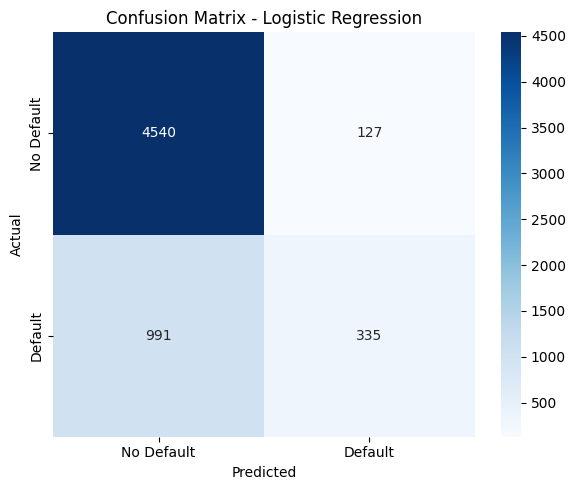

In [18]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 2. K-Nearest Neighbors (KNN)

KNN classifies a customer based on the classes of nearby observations. Feature scaling is important because KNN uses distances between observations.

In [19]:
# KNN Hyperparameter Tuning

knn_params = {
    "n_neighbors": [3, 5, 7, 9, 11, 15]
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=5,
    scoring="f1_weighted"
)

knn_grid.fit(
    X_train_processed,
    y_train
)

# Best KNN model
knn_model = knn_grid.best_estimator_

print("Best KNN Parameters:", knn_grid.best_params_)

# Predictions
y_pred_knn = knn_model.predict(
    X_test_processed
)

# Probability for ROC-AUC
y_prob_knn = knn_model.predict_proba(
    X_test_processed
)[:, 1]

# Evaluation
print("KNN completed!")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("Weighted F1-score:", f1_score(y_test, y_pred_knn, average="weighted"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))

Best KNN Parameters: {'n_neighbors': 15}
KNN completed!
Accuracy: 0.8082763223761055
Precision: 0.6224066390041494
Recall: 0.3393665158371041
Weighted F1-score: 0.7858822683725925
ROC-AUC: 0.7388503439153182


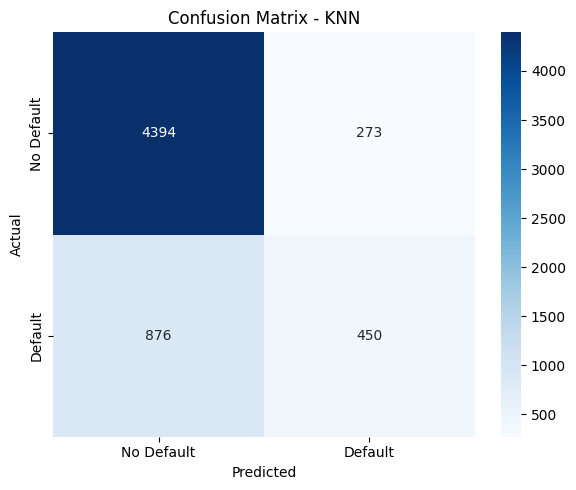

In [20]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 3. Gaussian Naive Bayes

Gaussian Naive Bayes is a probabilistic classifier based on Bayes' theorem and assumes conditional independence between features.

In [21]:
nb_model = GaussianNB()

nb_model.fit(
    X_train_processed,
    y_train
)

y_pred_nb = nb_model.predict(
    X_test_processed
)

y_prob_nb = nb_model.predict_proba(
    X_test_processed
)[:, 1]

print("Gaussian Naive Bayes completed!")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("Weighted F1-score:", f1_score(y_test, y_pred_nb, average="weighted"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_nb))

Gaussian Naive Bayes completed!
Accuracy: 0.3220423827799099
Precision: 0.23748321503932476
Recall: 0.9336349924585219
Weighted F1-score: 0.2816461361211992
ROC-AUC: 0.7244743507331893


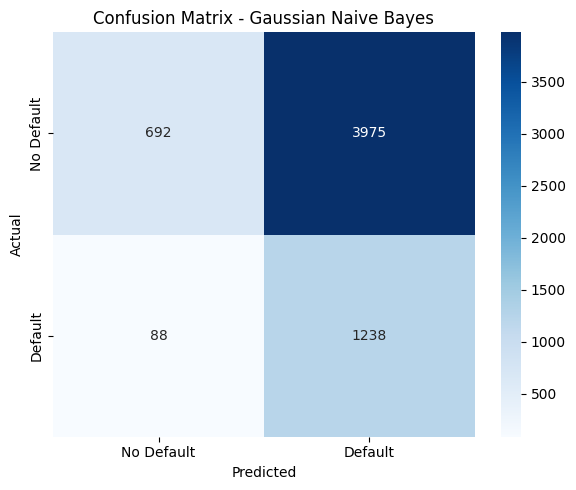

In [22]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 4. Decision Tree Classifier

Decision Tree Classifier predicts the target by creating a sequence of decision rules based on the input features.

In [23]:
# Decision Tree Hyperparameter Tuning

dt_params = {
    "max_depth": [3, 5, 7, 10, 15, None]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=5,
    scoring="f1_weighted"
)

dt_grid.fit(
    X_train_processed,
    y_train
)

# Best Decision Tree model
dt_model = dt_grid.best_estimator_

print("Best Decision Tree Parameters:", dt_grid.best_params_)

# Predictions
y_pred_dt = dt_model.predict(
    X_test_processed
)

# Probability for ROC-AUC
y_prob_dt = dt_model.predict_proba(
    X_test_processed
)[:, 1]

# Evaluation
print("Decision Tree completed!")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("Weighted F1-score:", f1_score(y_test, y_pred_dt, average="weighted"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

Best Decision Tree Parameters: {'max_depth': 5}
Decision Tree completed!
Accuracy: 0.8172868346404139
Precision: 0.6517739816031537
Recall: 0.3740573152337858
Weighted F1-score: 0.7977687698670646
ROC-AUC: 0.7446439669306103


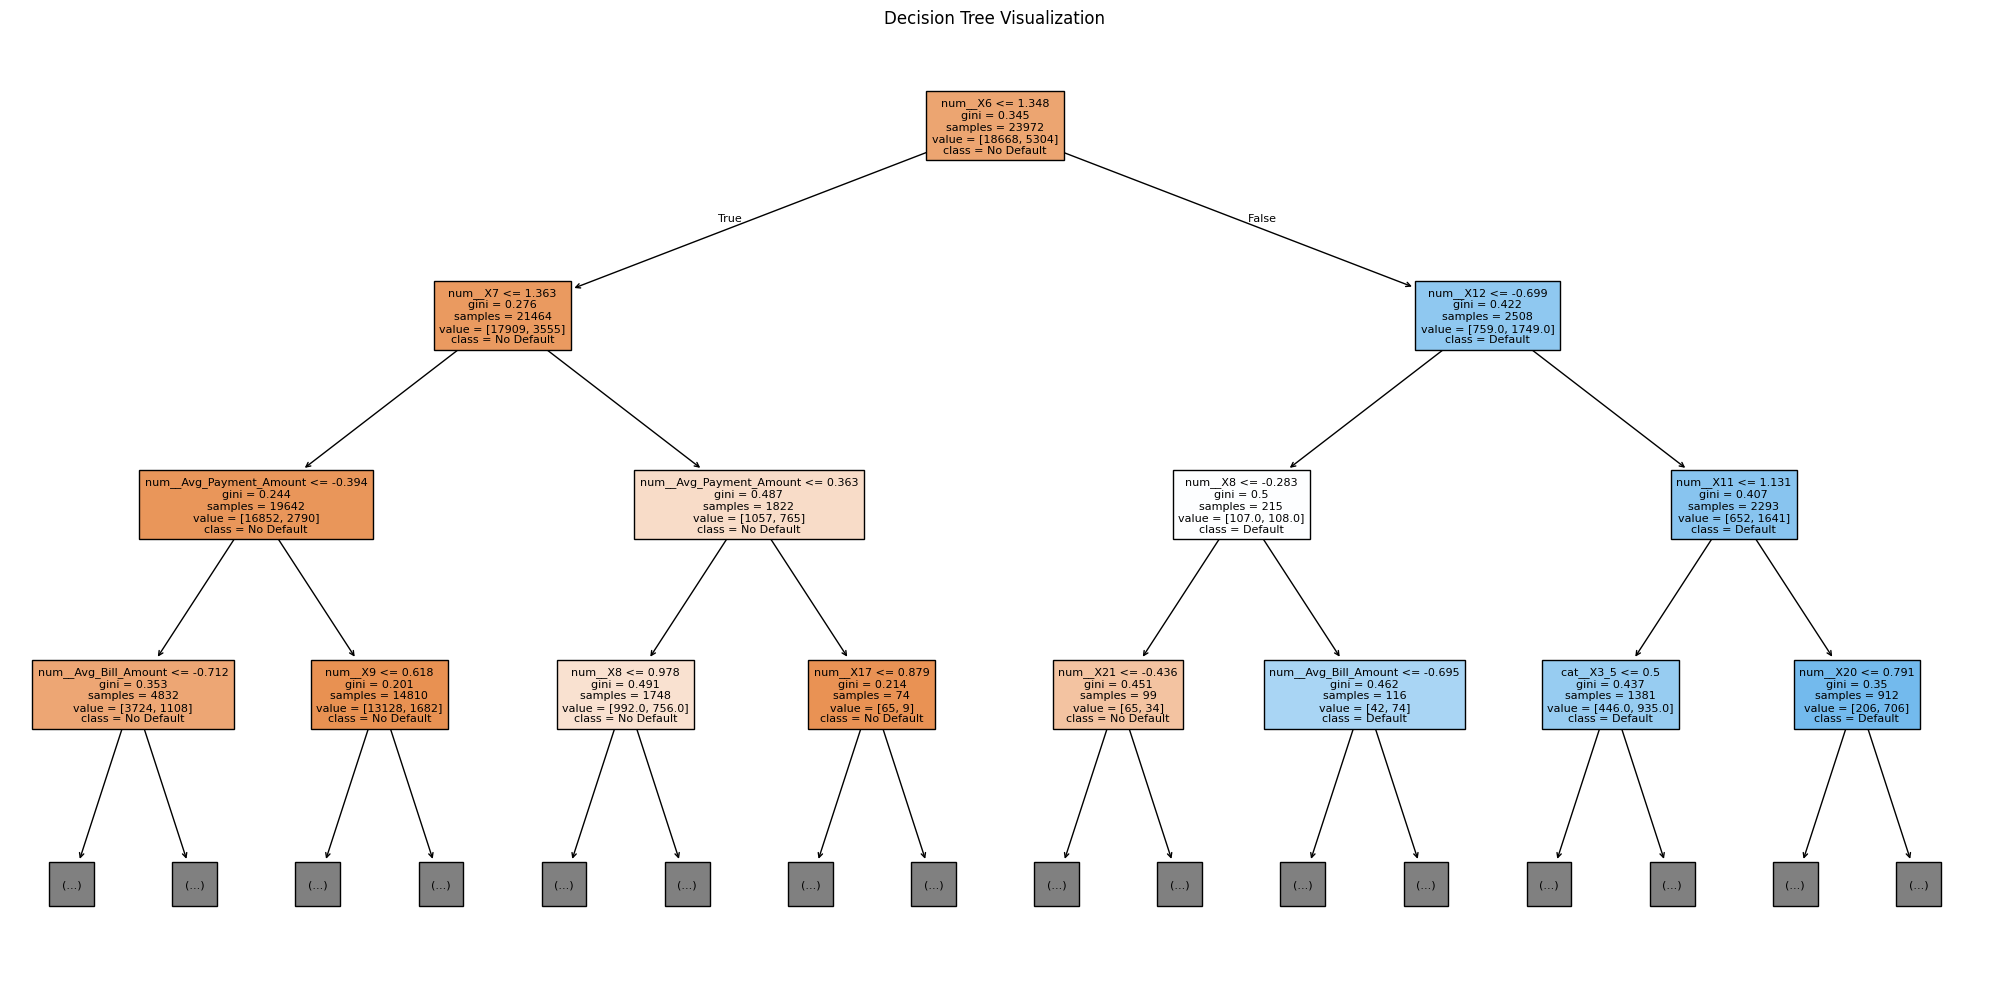

In [24]:
# Decision Tree Visualization

from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    max_depth=3,
    filled=True,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=["No Default", "Default"],
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

### Decision Tree Confusion Matrix

The confusion matrix shows the correct and incorrect predictions made by the Decision Tree classifier for the two classes: No Default and Default.

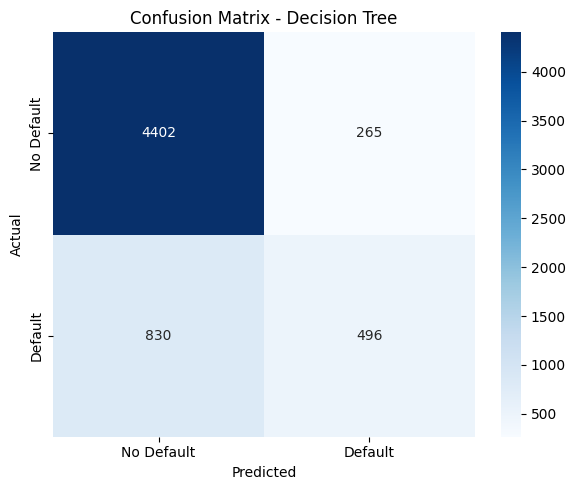

In [25]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 5. Support Vector Machine (SVM)

SVM is a classification algorithm that finds a decision boundary that separates the classes. The features are scaled before applying SVM.

SVM Results
-------------------------
Accuracy: 0.8091106290672451
Precision: 0.6986899563318777
Recall: 0.24132730015082957
Weighted F1-score: 0.7707928588750064
ROC-AUC: 0.691483413757453


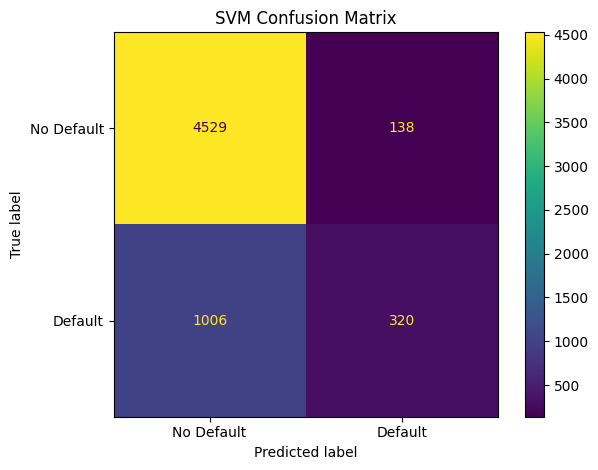

In [26]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create SVM model
svm_model = SVC(
    C=1,
    kernel="linear",
    random_state=42
)

# Train
svm_model.fit(X_train_processed, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test_processed)

# Evaluation
print("SVM Results")
print("-------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_svm, zero_division=0))
print(
    "Weighted F1-score:",
    f1_score(y_test, y_pred_svm, average="weighted", zero_division=0)
)

# ROC-AUC
y_score_svm = svm_model.decision_function(X_test_processed)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_score_svm)
)

# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

### SVM Hyperparameter Tuning

The SVM hyperparameters C and kernel were tuned using a validation subset of the training data. Different combinations of C values (0.1, 1, 10) and kernels (linear and RBF) were compared using validation accuracy. The selected parameters were then used to train the final SVM model.

In [27]:
# SVM Hyperparameter Tuning: C and Kernel

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd

# Use a small sample only for tuning
X_tune = X_train_processed[:1000]
y_tune = y_train[:1000]

# Split tuning data into training and validation sets
X_tune_train, X_tune_val, y_tune_train, y_tune_val = train_test_split(
    X_tune,
    y_tune,
    test_size=0.2,
    stratify=y_tune,
    random_state=42
)

C_values = [0.1, 1, 10]
kernel_values = ['linear', 'rbf']

svc_tuning_results = []

for C in C_values:
    for kernel in kernel_values:

        svc_model_temp = SVC(
            C=C,
            kernel=kernel,
            random_state=42
        )

        svc_model_temp.fit(
            X_tune_train,
            y_tune_train
        )

        y_pred = svc_model_temp.predict(X_tune_val)

        accuracy = accuracy_score(
            y_tune_val,
            y_pred
        )

        svc_tuning_results.append({
            'C': C,
            'Kernel': kernel,
            'Validation Accuracy': accuracy
        })

svc_tuning_df = pd.DataFrame(svc_tuning_results)

svc_tuning_df

,C,Kernel,Validation Accuracy
0,0.1,linear,0.855
1,0.1,rbf,0.760
2,1.0,linear,0.855
3,1.0,rbf,0.840
4,10.0,linear,0.855
5,10.0,rbf,0.805


In [28]:
# Final Tuned SVM Model

from sklearn.svm import SVC

# Select the best C and kernel based on validation accuracy
best_svc_row = svc_tuning_df.loc[
    svc_tuning_df["Validation Accuracy"].idxmax()
]

best_C = best_svc_row["C"]
best_kernel = best_svc_row["Kernel"]

print("Best SVM Parameters")
print("-------------------------")
print("C:", best_C)
print("Kernel:", best_kernel)
print("Validation Accuracy:", best_svc_row["Validation Accuracy"])

# Train final SVM using the best parameters
svm_tuned = SVC(
    C=best_C,
    kernel=best_kernel,
    random_state=42
)

svm_tuned.fit(
    X_train_processed,
    y_train
)

# Predictions
y_pred_svm_tuned = svm_tuned.predict(
    X_test_processed
)

# Decision scores for ROC-AUC
y_score_svm_tuned = svm_tuned.decision_function(
    X_test_processed
)

print("\nFinal Tuned SVM trained successfully!")

Best SVM Parameters
-------------------------
C: 0.1
Kernel: linear
Validation Accuracy: 0.855

Final Tuned SVM trained successfully!


## Comparison of Classification Part A Models

The five Classification Part A algorithms were evaluated using the same training and testing datasets and the same preprocessing pipeline.

The models are compared using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC. A summary table is presented below to compare the performance of all five algorithms.

In [29]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes",
        "Decision Tree",
        "SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_svm_tuned)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_nb, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0),
        precision_score(y_test, y_pred_svm_tuned, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_nb, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_svm_tuned, zero_division=0)
    ],

    "Weighted F1": [
        f1_score(y_test, y_pred_lr, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_knn, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_svm_tuned, average="weighted", zero_division=0)
    ],

    "ROC-AUC": [
        roc_auc_score(
            y_test,
            logistic_model.predict_proba(X_test_processed)[:, 1]
        ),
        roc_auc_score(
            y_test,
            knn_model.predict_proba(X_test_processed)[:, 1]
        ),
        roc_auc_score(
            y_test,
            nb_model.predict_proba(X_test_processed)[:, 1]
        ),
        roc_auc_score(
            y_test,
            dt_model.predict_proba(X_test_processed)[:, 1]
        ),
        roc_auc_score(
            y_test,
            y_score_svm_tuned
        )
    ]
})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Logistic Regression,0.8134,0.7251,0.2526,0.7763,0.7234
1,KNN,0.8083,0.6224,0.3394,0.7859,0.7389
2,Gaussian Naive Bayes,0.3220,0.2375,0.9336,0.2816,0.7245
3,Decision Tree,0.8173,0.6518,0.3741,0.7978,0.7446
4,SVM,0.8089,0.6972,0.2413,0.7707,0.6989


###  Preliminary Model Comparison

The five Classification Part A models are compared using **Accuracy** and **Weighted F1-score**. Confusion matrices are also provided for each model to examine the classification results across the classes.

The comparison provides a preliminary evaluation of the performance of Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, and the tuned SVM model.


In [30]:
# Review 1 D2 - Preliminary Classification Comparison

d2_comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes",
        "Decision Tree",
        "SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_svm_tuned)
    ],

    "Weighted F1": [
        f1_score(y_test, y_pred_lr, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_knn, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_dt, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_svm_tuned, average="weighted", zero_division=0)
    ],

    "Confusion Matrix": [
        str(confusion_matrix(y_test, y_pred_lr)),
        str(confusion_matrix(y_test, y_pred_knn)),
        str(confusion_matrix(y_test, y_pred_nb)),
        str(confusion_matrix(y_test, y_pred_dt)),
        str(confusion_matrix(y_test, y_pred_svm_tuned))
    ]
})

d2_comparison_df.round(4)

,Model,Accuracy,Weighted F1,Confusion Matrix
0,Logistic Regression,0.8134,0.7763,[[4540 127]\n [ 991 335]]
1,KNN,0.8083,0.7859,[[4394 273]\n [ 876 450]]
2,Gaussian Naive Bayes,0.3220,0.2816,[[ 692 3975]\n [ 88 1238]]
3,Decision Tree,0.8173,0.7978,[[4402 265]\n [ 830 496]]
4,SVM,0.8089,0.7707,[[4528 139]\n [1006 320]]


## Visual Comparison of Classification Models

The performance of the five Classification Part A models is compared visually using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC. This visualization helps compare the models across the different evaluation metrics.

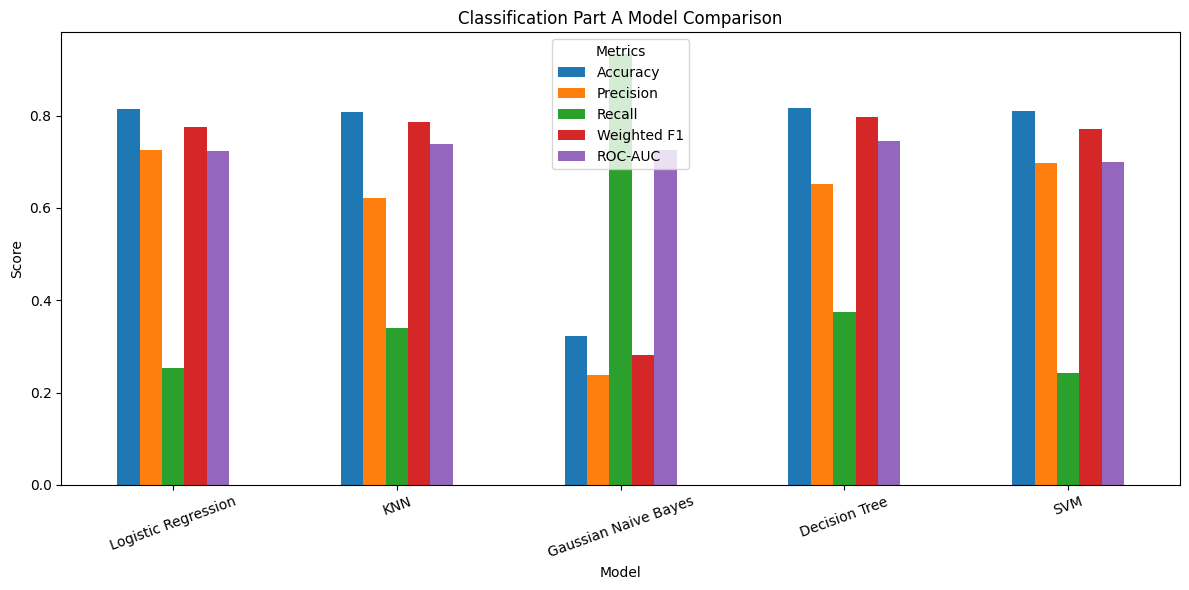

In [31]:
comparison_plot = comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "Weighted F1", "ROC-AUC"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Part A Model Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

## 5-Fold Cross-Validation

To assess the stability and generalization performance of the classification models, 5-fold cross-validation was performed on the two selected models: Decision Tree and K-Nearest Neighbors (KNN).

The **weighted F1-score** was used as the evaluation metric. The mean weighted F1-score represents the average performance across the five folds, while the standard deviation indicates the variation in performance between folds.

The cross-validation results are presented below for comparison.


In [32]:
from sklearn.model_selection import cross_val_score

# 5-Fold Cross-Validation for Decision Tree
dt_cv_scores = cross_val_score(
    dt_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring="f1_weighted"
)

# 5-Fold Cross-Validation for KNN
knn_cv_scores = cross_val_score(
    knn_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring="f1_weighted"
)

cv_results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Mean CV Weighted F1": [
        dt_cv_scores.mean(),
        knn_cv_scores.mean()
    ],
    "Std CV Weighted F1": [
        dt_cv_scores.std(),
        knn_cv_scores.std()
    ]
})

cv_results.round(4)

,Model,Mean CV Weighted F1,Std CV Weighted F1
0,Decision Tree,0.7978,0.006
1,KNN,0.7872,0.006


## Conclusion

The five Classification Part A algorithms were successfully implemented and evaluated on the same test dataset. Their performance was compared using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC.

The confusion matrices and comparison visualization provide an overall view of the classification performance. The results from this stage will serve as the baseline for further classification work in Review 2.

## End of Classification Part A

Classification Part A is complete with all five required algorithms, their evaluation metrics, confusion matrices, and the preliminary model comparison.

## Classification Part B — Review 2

Classification Part B extends the existing Credit Card Default Prediction project by implementing five additional classification algorithms. All models use the same preprocessed training and testing datasets used in Part A. Their performance is evaluated using Accuracy, Precision, Recall, Weighted F1-score, ROC-AUC, and confusion matrices.

### 6. Random Forest Classifier

Random Forest combines multiple decision trees to predict credit card default. It also helps identify important features influencing the predictions.


Original Random Forest Results
Accuracy: 0.8139
Precision: 0.6522
Recall: 0.3409
Weighted F1: 0.7907
ROC-AUC: 0.7604


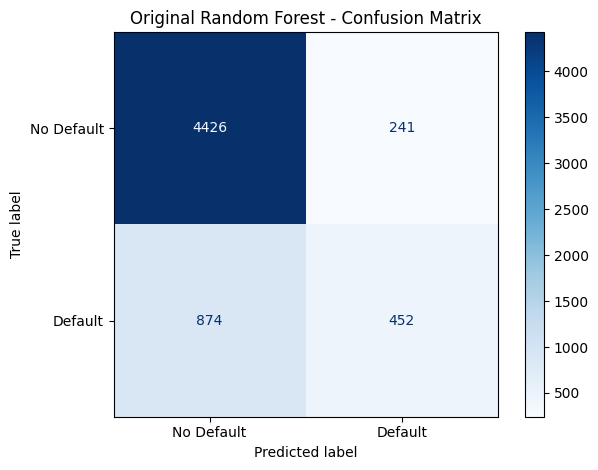

Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best Parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best CV Weighted F1: 0.7986

Tuned Random Forest Results
Accuracy: 0.8071
Precision: 0.5884
Recall: 0.4268
Weighted F1: 0.7954
ROC-AUC: 0.7669


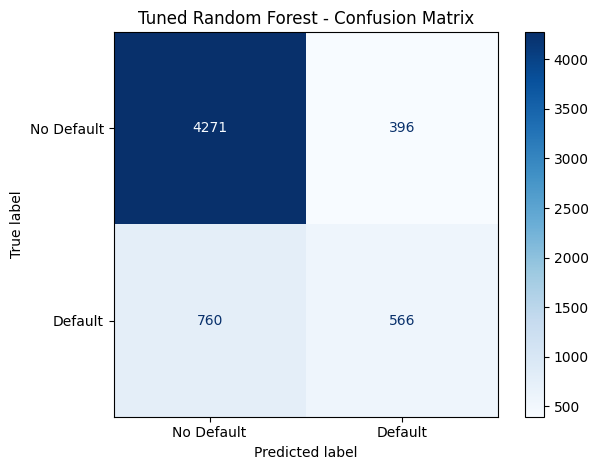


Original vs Tuned Random Forest


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Original Random Forest,0.8139,0.6522,0.3409,0.7907,0.7604
1,Tuned Random Forest,0.8071,0.5884,0.4268,0.7954,0.7669


Original Weighted F1: 0.7907
Tuned Weighted F1: 0.7954
Change in Weighted F1: +0.0047
Tuning improved Weighted F1.


In [55]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# 1. Evaluation function
def evaluate_rf(model, model_name):
    y_pred = model.predict(X_test_processed)
    y_score = model.predict_proba(X_test_processed)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    }

    print(f"\n{model_name} Results")
    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["No Default", "Default"],
        cmap="Blues"
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return results


# 2. Train and evaluate original Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train_processed, y_train)
rf_results = evaluate_rf(rf_model, "Original Random Forest")


# 3. Hyperparameter tuning
rf_param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ),
    param_distributions=rf_param_grid,
    n_iter=6,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_processed, y_train)

rf_tuned = rf_search.best_estimator_

print("\nBest Parameters:")
print(rf_search.best_params_)

print("Best CV Weighted F1:", round(rf_search.best_score_, 4))


# 4. Evaluate tuned Random Forest
rf_tuned_results = evaluate_rf(rf_tuned, "Tuned Random Forest")


# 5. Compare original and tuned models
rf_comparison = pd.DataFrame([
    rf_results,
    rf_tuned_results
])

print("\nOriginal vs Tuned Random Forest")
display(rf_comparison.round(4))

original_f1 = rf_results["Weighted F1"]
tuned_f1 = rf_tuned_results["Weighted F1"]

print(f"Original Weighted F1: {original_f1:.4f}")
print(f"Tuned Weighted F1: {tuned_f1:.4f}")
print(f"Change in Weighted F1: {tuned_f1 - original_f1:+.4f}")

if tuned_f1 > original_f1:
    print("Tuning improved Weighted F1.")
elif tuned_f1 < original_f1:
    print("Tuning did not improve Weighted F1.")
else:
    print("Weighted F1 remained unchanged.")

### Random Forest Feature Importance

Feature importance helps identify which input features contribute most to the predictions made by the tuned Random Forest model. The model assigns an importance score to each feature based on its contribution to reducing impurity across the decision trees.

The top 10 features are visualized using a horizontal bar chart, allowing us to identify the most influential features in the classification task. Higher importance scores indicate a greater contribution to the model's predictions.

**Purpose:** To interpret the tuned Random Forest model and understand which features have the greatest influence on its predictions.

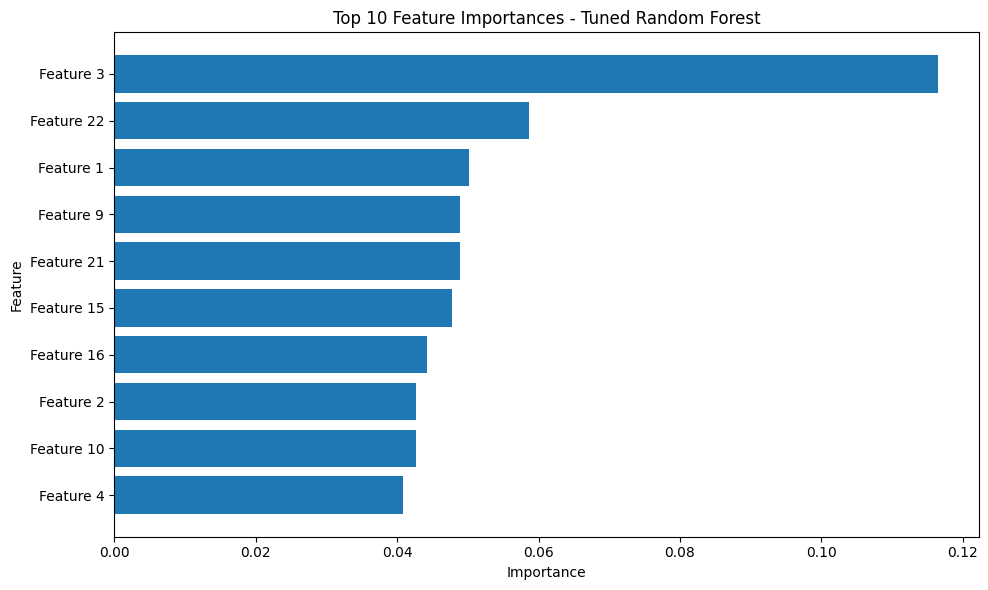

,Feature,Importance
2,Feature 3,0.116422
21,Feature 22,0.058644
0,Feature 1,0.050130
8,Feature 9,0.048868
20,Feature 21,0.048840
14,Feature 15,0.047813
15,Feature 16,0.044305
1,Feature 2,0.042673
9,Feature 10,0.042635
3,Feature 4,0.040870


In [57]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = [f"Feature {i+1}" for i in range(X_train_processed.shape[1])]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_tuned.feature_importances_
}).sort_values("Importance", ascending=False)

top10 = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.title("Top 10 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df)

#### Feature Importance

Feature importance identifies which customer attributes contribute most to the Random Forest model's predictions.

,Feature,Importance
2,num__X6,0.0947
21,num__Avg_Payment_Amount,0.0591
0,num__X1,0.0567
1,num__X5,0.0539
20,num__Avg_Bill_Amount,0.0510
8,num__X12,0.0510
14,num__X18,0.0468
9,num__X13,0.0443
15,num__X19,0.0435
11,num__X15,0.0421


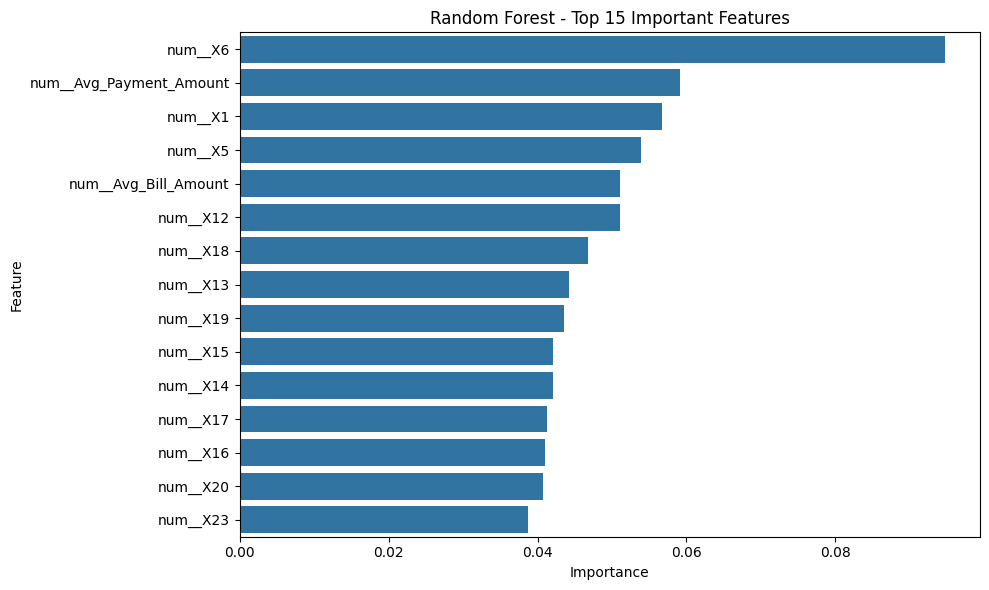

In [35]:
feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(rf_importance.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=rf_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### AdaBoost: Original vs Tuned Model

The original AdaBoost model is trained and evaluated using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC. Hyperparameter tuning is performed using `RandomizedSearchCV` to find the best values for `n_estimators` and `learning_rate`, using weighted F1-score as the evaluation metric.

The tuned model is evaluated using the same metrics and compared with the original model to measure the improvement in classification performance.


Original AdaBoost Results
-----------------------------------
Accuracy: 0.8160
Precision: 0.6713
Recall: 0.3296
Weighted F1: 0.7907
ROC-AUC: 0.7546


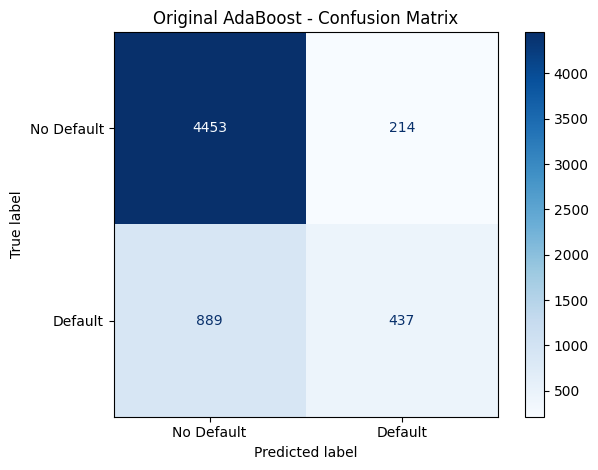

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'n_estimators': 150, 'learning_rate': 0.5}
Best CV Weighted F1: 0.7948

Tuned AdaBoost Results
-----------------------------------
Accuracy: 0.8163
Precision: 0.6662
Recall: 0.3401
Weighted F1: 0.7925
ROC-AUC: 0.7624


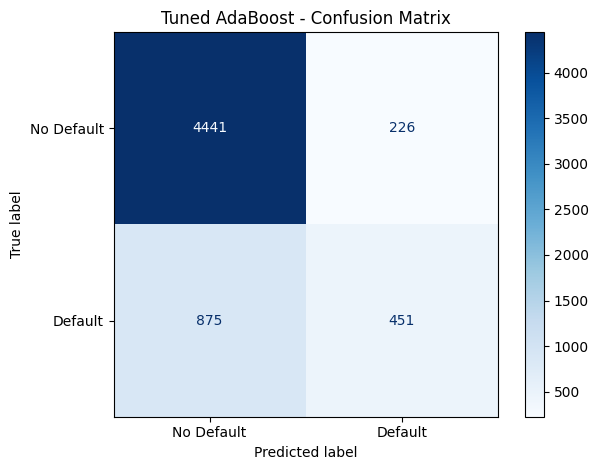

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Original AdaBoost,0.815952,0.671275,0.329563,0.790739,0.754567
1,Tuned AdaBoost,0.816286,0.666174,0.340121,0.792494,0.762404


Weighted F1 Improvement: 0.0018


In [58]:
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import RandomizedSearchCV

# Original AdaBoost
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train_processed, y_train)

ada_results, y_pred_ada = evaluate_part_b_model(
    ada_model, "Original AdaBoost"
)

# Hyperparameter Tuning
ada_params = {
    "n_estimators": [50, 100, 150, 200, 250],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0, 1.5]
}

ada_search = RandomizedSearchCV(
    AdaBoostClassifier(random_state=42),
    param_distributions=ada_params,
    n_iter=10,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

ada_search.fit(X_train_processed, y_train)

ada_tuned = ada_search.best_estimator_

print("Best Parameters:", ada_search.best_params_)
print("Best CV Weighted F1:", round(ada_search.best_score_, 4))

# Tuned Model Evaluation
ada_tuned_results, y_pred_ada_tuned = evaluate_part_b_model(
    ada_tuned, "Tuned AdaBoost"
)

# Original vs Tuned Comparison
ada_comparison = pd.DataFrame([
    ada_results,
    ada_tuned_results
])

display(ada_comparison)

# Weighted F1 Improvement
print(
    "Weighted F1 Improvement:",
    round(
        ada_tuned_results["Weighted F1"] -
        ada_results["Weighted F1"], 4
    )
)

### AdaBoost Feature Importance

Feature importance is extracted from the tuned AdaBoost model to identify the most influential features in the classification task. A horizontal bar chart visualizes the top 10 features based on their importance scores.

This analysis helps interpret the model's predictions and understand which features contribute most to its classification decisions.

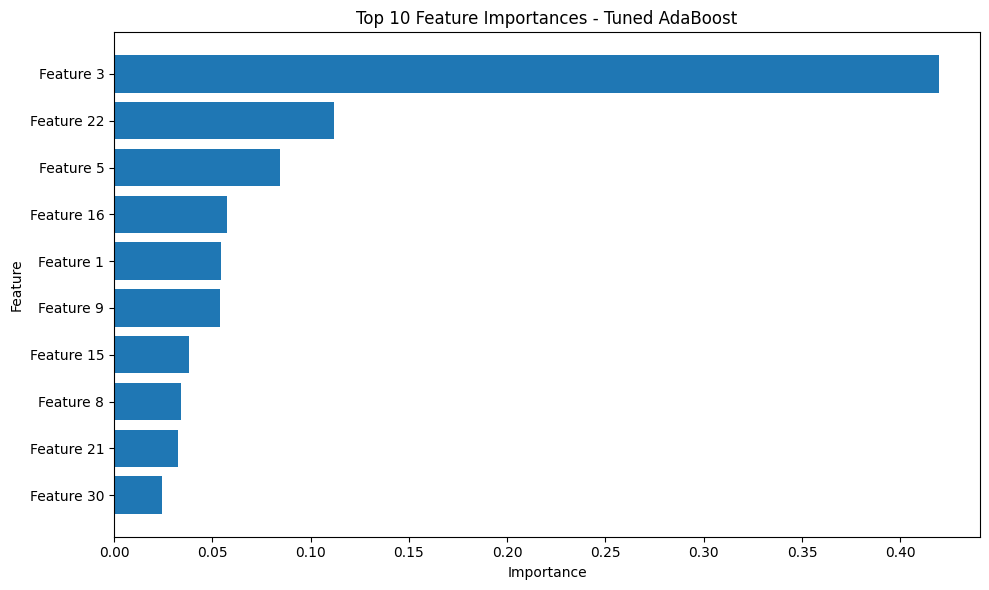

,Feature,Importance
2,Feature 3,0.419564
21,Feature 22,0.111690
4,Feature 5,0.084628
15,Feature 16,0.057446
0,Feature 1,0.054314
8,Feature 9,0.054085
14,Feature 15,0.038051
7,Feature 8,0.034189
20,Feature 21,0.032340
29,Feature 30,0.024222


In [59]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = [
    f"Feature {i+1}"
    for i in range(X_train_processed.shape[1])
]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": ada_tuned.feature_importances_
}).sort_values("Importance", ascending=False)

top10 = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.title("Top 10 Feature Importances - Tuned AdaBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df)

### Gradient Boosting: Original vs Tuned Model

The original Gradient Boosting model is trained and evaluated using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC. Hyperparameter tuning is performed using `RandomizedSearchCV` to identify the best combination of `n_estimators`, `learning_rate`, `max_depth`, and `subsample`, using weighted F1-score as the selection metric.

The tuned model is evaluated using the same metrics and compared with the original model to determine whether hyperparameter tuning improves classification performance.


Original Gradient Boosting Results
-----------------------------------
Accuracy: 0.8176
Precision: 0.6616
Recall: 0.3597
Weighted F1: 0.7962
ROC-AUC: 0.7723


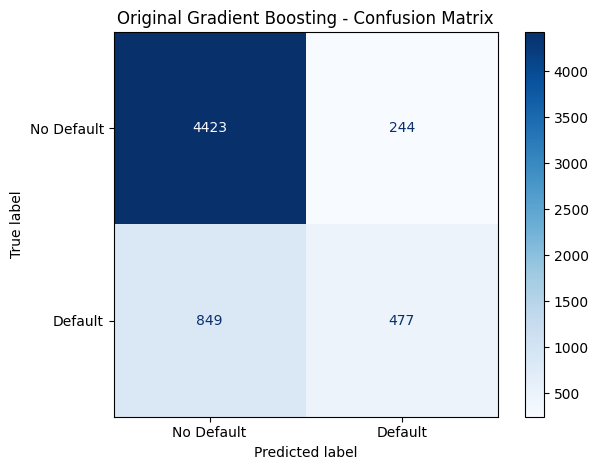

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'subsample': 0.8, 'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 4, 'learning_rate': 0.1}
Best CV Weighted F1: 0.8016

Tuned Gradient Boosting Results
-----------------------------------
Accuracy: 0.8185
Precision: 0.6621
Recall: 0.3665
Weighted F1: 0.7978
ROC-AUC: 0.7727


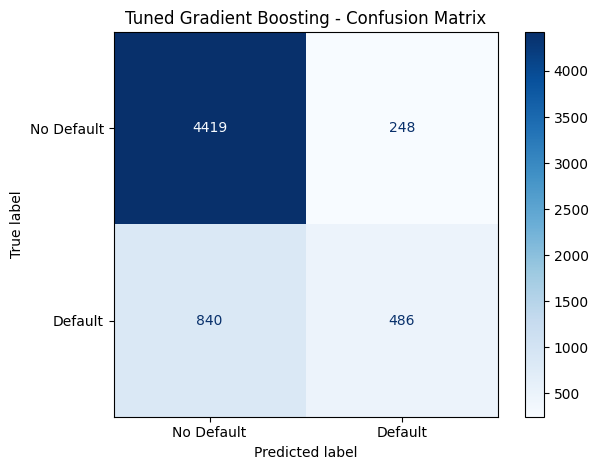

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Original Gradient Boosting,0.817621,0.661581,0.359729,0.796220,0.772303
1,Tuned Gradient Boosting,0.818455,0.662125,0.366516,0.797783,0.772714


Weighted F1 Improvement: 0.0016


In [60]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

# 1. Original Gradient Boosting Model
gb_model = GradientBoostingClassifier(random_state=42)

gb_model.fit(X_train_processed, y_train)

gb_results, y_pred_gb = evaluate_part_b_model(
    gb_model, "Original Gradient Boosting"
)

# 2. Hyperparameter Tuning
gb_params = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.8, 0.9, 1.0],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

gb_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=gb_params,
    n_iter=10,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train_processed, y_train)

gb_tuned = gb_search.best_estimator_

print("Best Parameters:", gb_search.best_params_)
print("Best CV Weighted F1:", round(gb_search.best_score_, 4))

# 3. Tuned Model Evaluation
gb_tuned_results, y_pred_gb_tuned = evaluate_part_b_model(
    gb_tuned, "Tuned Gradient Boosting"
)

# 4. Original vs Tuned Comparison
gb_comparison = pd.DataFrame([
    gb_results,
    gb_tuned_results
])

display(gb_comparison)

# 5. Weighted F1 Improvement
print(
    "Weighted F1 Improvement:",
    round(
        gb_tuned_results["Weighted F1"] -
        gb_results["Weighted F1"], 4
    )
)

### Gradient Boosting Feature Importance

Feature importance is extracted from the tuned Gradient Boosting model to identify the features that contribute most to its predictions. A horizontal bar chart displays the top 10 most important features based on their importance scores.

This analysis helps interpret the model and understand which input features have the greatest influence on the classification results.

,Feature,Importance
2,num__X6,0.5030
3,num__X7,0.0752
21,num__Avg_Payment_Amount,0.0449
4,num__X8,0.0378
8,num__X12,0.0371
0,num__X1,0.0355
20,num__Avg_Bill_Amount,0.0351
14,num__X18,0.0224
16,num__X20,0.0212
5,num__X9,0.0205


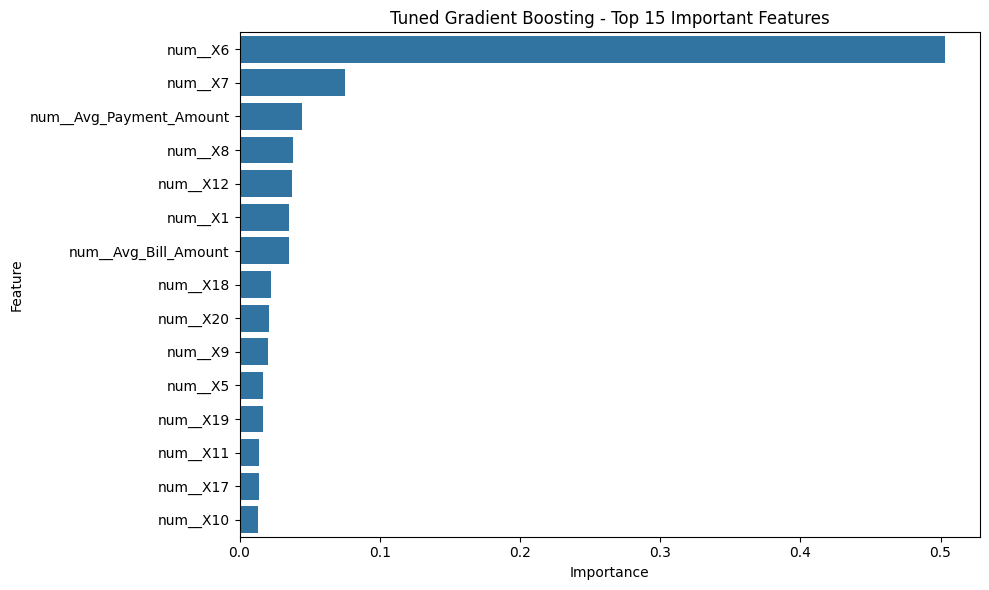

In [64]:
# 6. Feature Importance - Tuned Gradient Boosting

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_tuned.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Tuned Gradient Boosting - Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# BAGGING CLASSIFIER: ORIGINAL VS TUNED MODEL

The original Bagging Classifier uses Decision Trees as base estimators to improve classification stability by training multiple models on bootstrap samples. Hyperparameter tuning is performed using RandomizedSearchCV to identify suitable parameters, including the number of estimators, maximum samples, and maximum features, using weighted F1-score as the selection metric.

The tuned model is evaluated using the same metrics and compared with the original model to determine whether hyperparameter tuning improves classification performance.


Original Bagging Classifier Results
-----------------------------------
Accuracy: 0.8006
Precision: 0.5914
Recall: 0.3198
Weighted F1: 0.7770
ROC-AUC: 0.7274


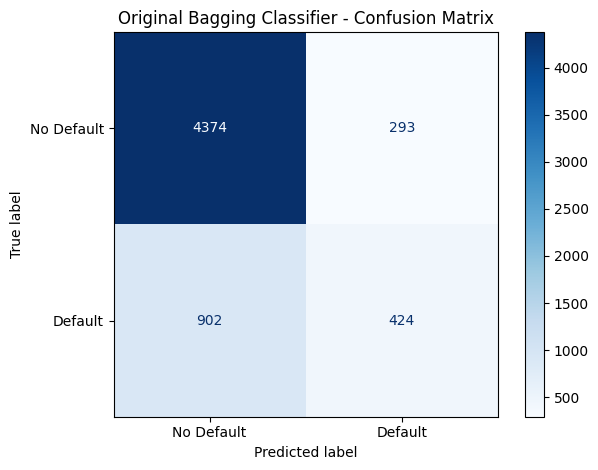

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'n_estimators': 150, 'max_samples': 0.8, 'max_features': 0.8, 'estimator__min_samples_split': 10, 'estimator__max_depth': 5, 'bootstrap': True}
Best CV Weighted F1: 0.7986

Tuned Bagging Classifier Results
-----------------------------------
Accuracy: 0.8190
Precision: 0.6769
Recall: 0.3477
Weighted F1: 0.7957
ROC-AUC: 0.7650


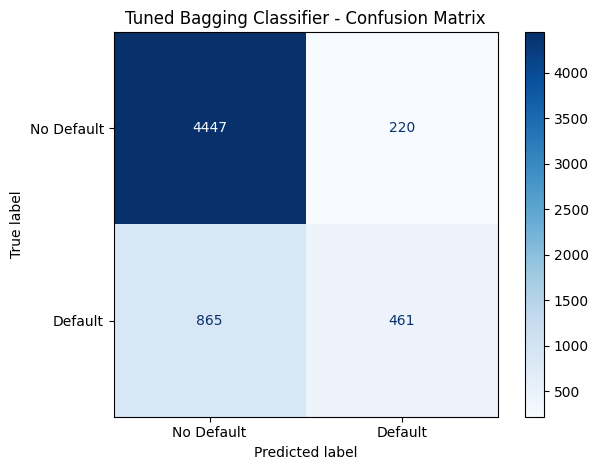

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Original Bagging Classifier,0.800601,0.591353,0.319759,0.776988,0.727446
1,Tuned Bagging Classifier,0.818955,0.676946,0.347662,0.795715,0.764988


Weighted F1 Improvement: 0.0187


In [79]:
import pandas as pd
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV

# 1. Original Bagging Model
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

bagging_model.fit(X_train_processed, y_train)

bagging_results, y_pred_bagging = evaluate_part_b_model(
    bagging_model, "Original Bagging Classifier"
)

# 2. Hyperparameter Tuning
bagging_params = {
    "n_estimators": [50, 100, 150, 200],
    "max_samples": [0.6, 0.8, 1.0],
    "max_features": [0.6, 0.8, 1.0],
    "bootstrap": [True, False],
    "estimator__max_depth": [None, 5, 10, 15],
    "estimator__min_samples_split": [2, 5, 10]
}

bagging_search = RandomizedSearchCV(
    estimator=BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42
    ),
    param_distributions=bagging_params,
    n_iter=10,
    scoring="f1_weighted",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

bagging_search.fit(X_train_processed, y_train)

bagging_tuned = bagging_search.best_estimator_

print("Best Parameters:", bagging_search.best_params_)
print("Best CV Weighted F1:", round(bagging_search.best_score_, 4))

bagging_tuned_results, y_pred_bagging_tuned = evaluate_part_b_model(
    bagging_tuned, "Tuned Bagging Classifier"
)

bagging_comparison = pd.DataFrame([
    bagging_results,
    bagging_tuned_results
])

display(bagging_comparison)

print(
    "Weighted F1 Improvement:",
    round(
        bagging_tuned_results["Weighted F1"]
        - bagging_results["Weighted F1"],
        4
    )
)

### Feature Importance – Bagging Classifier

Feature importance is used to identify which input features contribute most to the model's predictions. In a Bagging Classifier, feature importance can be calculated by averaging the feature importances of the base estimators if they support it.

The features are ranked based on their importance scores, where higher values indicate greater contribution to the model.

,Feature,Importance
3,Feature 3,0.0424
8,Feature 8,0.0395
12,Feature 12,0.0390
4,Feature 4,0.0389
9,Feature 9,0.0382
25,Feature 25,0.0377
26,Feature 26,0.0369
1,Feature 1,0.0366
5,Feature 5,0.0366
17,Feature 17,0.0363


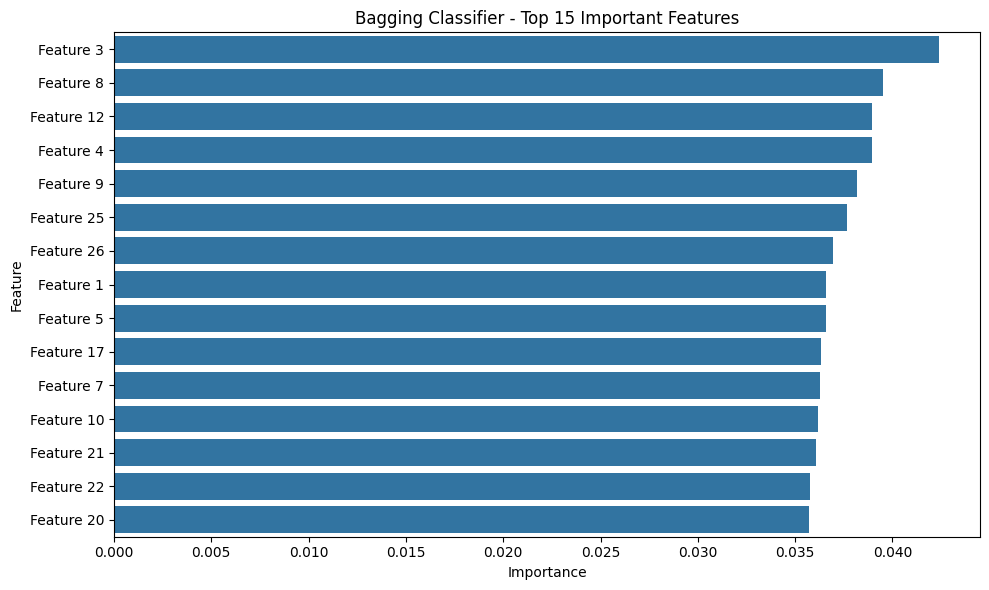

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get average feature importance across all trees
importances = np.mean(
    [tree.feature_importances_ for tree in bagging_tuned.estimators_],
    axis=0
)

# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Fix mismatched lengths
if len(feature_names) != len(importances):
    feature_names = [f"Feature {i}" for i in range(len(importances))]

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

display(feature_importance.head(15).round(4))

# Plot top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Bagging Classifier - Top 15 Important Features")
plt.tight_layout()
plt.show()

# MLP Classifier: Original vs Tuned Model

The MLP Classifier is trained and evaluated using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC. Hyperparameter tuning is performed using `GridSearchCV` to identify the best combination of `hidden_layer_sizes` and `activation`, using weighted F1-score as the selection metric.

The tuned model is evaluated using the same metrics and compared with the original model to determine whether hyperparameter tuning improves classification performance.


Original MLP Results
-----------------------------------
Accuracy: 0.8155
Precision: 0.6410
Recall: 0.3771
Weighted F1: 0.7966
ROC-AUC: 0.7598


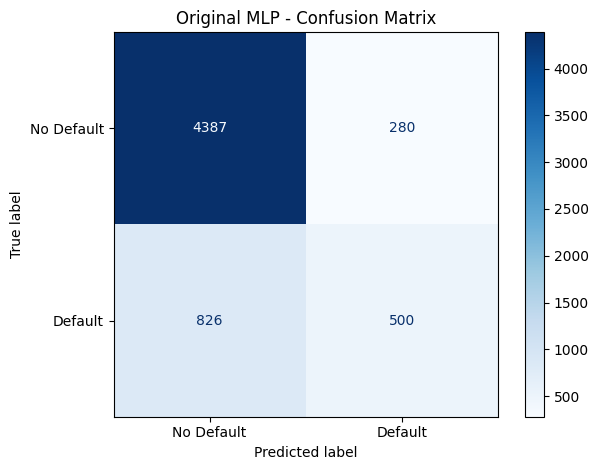

Best MLP Parameters: {'activation': 'relu', 'hidden_layer_sizes': (64, 32)}
Best CV Weighted F1: 0.7982

Tuned MLP Results
-----------------------------------
Accuracy: 0.8185
Precision: 0.6648
Recall: 0.3620
Weighted F1: 0.7972
ROC-AUC: 0.7655


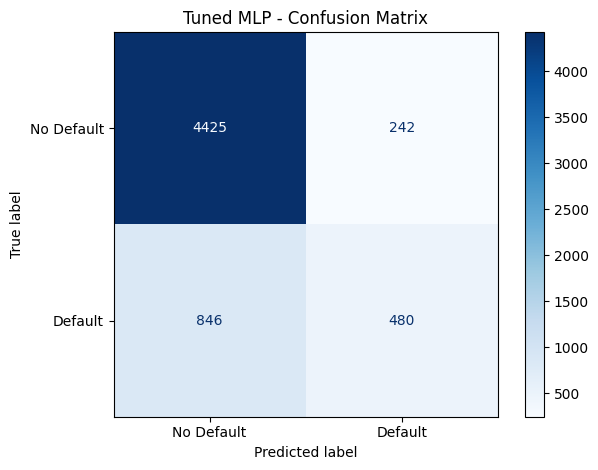

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Original MLP,0.815451,0.641026,0.377074,0.796628,0.759834
1,Tuned MLP,0.818455,0.664820,0.361991,0.797201,0.765488


Weighted F1 Improvement: 0.0006


In [67]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
import pandas as pd

# 1. Original MLP Model
mlp_original = MLPClassifier(
    max_iter=300,
    early_stopping=True,
    random_state=42
)

mlp_original.fit(X_train_processed, y_train)

mlp_results, y_pred_mlp = evaluate_part_b_model(
    mlp_original, "Original MLP"
)

# 2. Hyperparameter Tuning
mlp_params = {
    "hidden_layer_sizes": [(32,), (64,), (64, 32)],
    "activation": ["relu", "tanh"]
}

mlp_grid = GridSearchCV(
    estimator=MLPClassifier(
        max_iter=300,
        early_stopping=True,
        random_state=42
    ),
    param_grid=mlp_params,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

mlp_grid.fit(X_train_processed, y_train)

mlp_tuned = mlp_grid.best_estimator_

print("Best MLP Parameters:", mlp_grid.best_params_)
print("Best CV Weighted F1:", round(mlp_grid.best_score_, 4))

# 3. Tuned Model Evaluation
mlp_tuned_results, y_pred_mlp_tuned = evaluate_part_b_model(
    mlp_tuned, "Tuned MLP"
)

# 4. Original vs Tuned Comparison
mlp_comparison = pd.DataFrame([
    mlp_results,
    mlp_tuned_results
])

display(mlp_comparison)

# 5. Weighted F1 Improvement
print(
    "Weighted F1 Improvement:",
    round(
        mlp_tuned_results["Weighted F1"] -
        mlp_results["Weighted F1"], 4
    )
)

# MLP CLASSIFIER FEATURE IMPORTANCE

Feature importance is analyzed using permutation importance on the tuned MLP Classifier to identify the features that contribute most to its predictions. The top 15 features are displayed in a horizontal bar chart based on their mean decrease in weighted F1-score when each feature is shuffled.

This analysis helps interpret the model and understand the influence of individual features on classification performance.

,Feature,Importance
2,num__X6,0.0901
0,num__X1,0.0095
7,num__X11,0.0053
22,cat__X2_1,0.0037
4,num__X8,0.0035
23,cat__X2_2,0.0035
8,num__X12,0.0034
33,cat__X4_2,0.0034
6,num__X10,0.0031
15,num__X19,0.0026


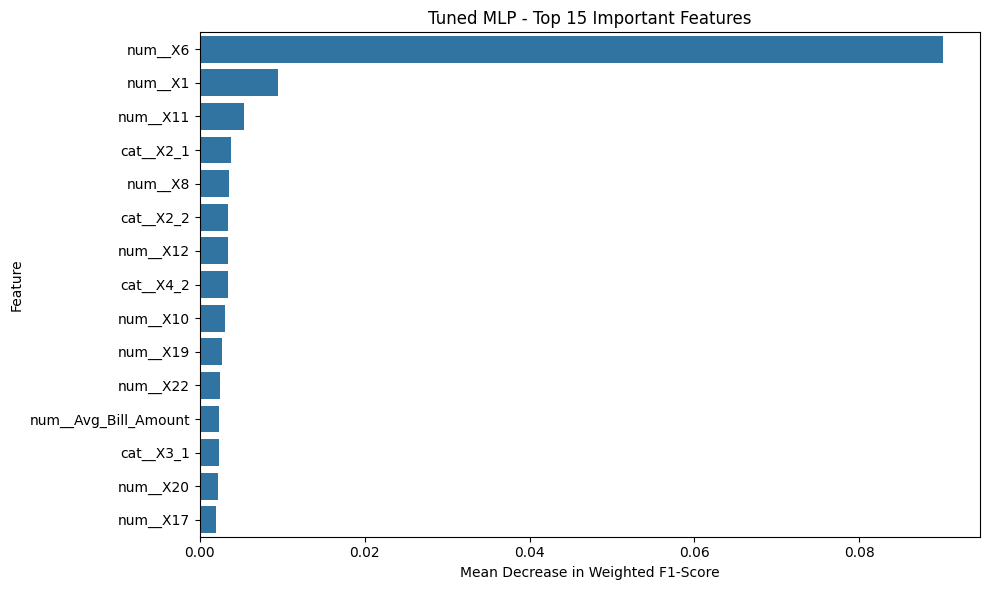

In [69]:
# 6. Feature Importance - Tuned MLP

from sklearn.inspection import permutation_importance

feature_names = preprocessor.get_feature_names_out()

result = permutation_importance(
    mlp_tuned,
    X_test_processed,
    y_test,
    scoring="f1_weighted",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": result.importances_mean
}).sort_values(by="Importance", ascending=False)

display(feature_importance.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Tuned MLP - Top 15 Important Features")
plt.xlabel("Mean Decrease in Weighted F1-Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 5-Fold Cross-Validation for All 10 Classification Models

Stratified 5-fold cross-validation was performed using weighted F1-score to compare the performance and consistency of all ten classification models. The mean weighted F1-score and standard deviation were calculated for each model. Random Forest and Gradient Boosting achieved the highest mean cross-validation scores in this evaluation.

In [82]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.base import clone
import pandas as pd

cv_models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model,
    "Decision Tree": dt_model,
    "SVM": svm_tuned,
    "Random Forest": rf_tuned,
    "AdaBoost": ada_tuned,
    "Gradient Boosting": gb_tuned,
    "Bagging": bagging_tuned,
    "MLP Neural Network": mlp_tuned
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in cv_models.items():
    scores = cross_val_score(
        clone(model),
        X_train_processed,
        y_train,
        cv=cv,
        scoring="f1_weighted",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Weighted F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values(
        "Mean Weighted F1",
        ascending=False
    ).round(4)
)

,Model,Mean Weighted F1,Standard Deviation
7,Gradient Boosting,0.8012,0.0065
5,Random Forest,0.8010,0.0035
8,Bagging,0.7985,0.0064
9,MLP Neural Network,0.7984,0.0052
3,Decision Tree,0.7974,0.0063
6,AdaBoost,0.7963,0.0042
1,KNN,0.7860,0.0037
0,Logistic Regression,0.7707,0.0034
4,SVM,0.7707,0.0041
2,Gaussian Naive Bayes,0.2885,0.0044


### 12. Comparison of All 10 Classification Algorithms

The results from Classification Parts A and B are combined to compare all ten algorithms using Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC. The tuned Random Forest is used in the final comparison.

In [85]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

all_models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model,
    "Decision Tree": dt_model,
    "SVM": svm_tuned,
    "Random Forest": rf_tuned,
    "AdaBoost": ada_tuned,
    "Gradient Boosting": gb_tuned,
    "Bagging": bagging_tuned,
    "MLP Neural Network": mlp_tuned
}

comparison_results = []

for name, model in all_models.items():
    y_pred = model.predict(X_test_processed)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_score = model.decision_function(X_test_processed)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

final_comparison_df = pd.DataFrame(comparison_results)

final_comparison_df = final_comparison_df.sort_values(
    "Weighted F1", ascending=False
).reset_index(drop=True)

display(final_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Gradient Boosting,0.8185,0.6621,0.3665,0.7978,0.7727
1,Decision Tree,0.8173,0.6518,0.3741,0.7978,0.7446
2,MLP Neural Network,0.8185,0.6648,0.3620,0.7972,0.7655
3,Bagging,0.8190,0.6769,0.3477,0.7957,0.7650
4,Random Forest,0.8071,0.5884,0.4268,0.7954,0.7669
5,AdaBoost,0.8163,0.6662,0.3401,0.7925,0.7624
6,KNN,0.8083,0.6224,0.3394,0.7859,0.7389
7,Logistic Regression,0.8134,0.7251,0.2526,0.7763,0.7234
8,SVM,0.8089,0.6972,0.2413,0.7707,0.6989
9,Gaussian Naive Bayes,0.3220,0.2375,0.9336,0.2816,0.7245


### 13. Visual Comparison of Classification Models

A grouped bar chart compares the five evaluation metrics across all ten classifiers to make their relative performance easier to interpret.

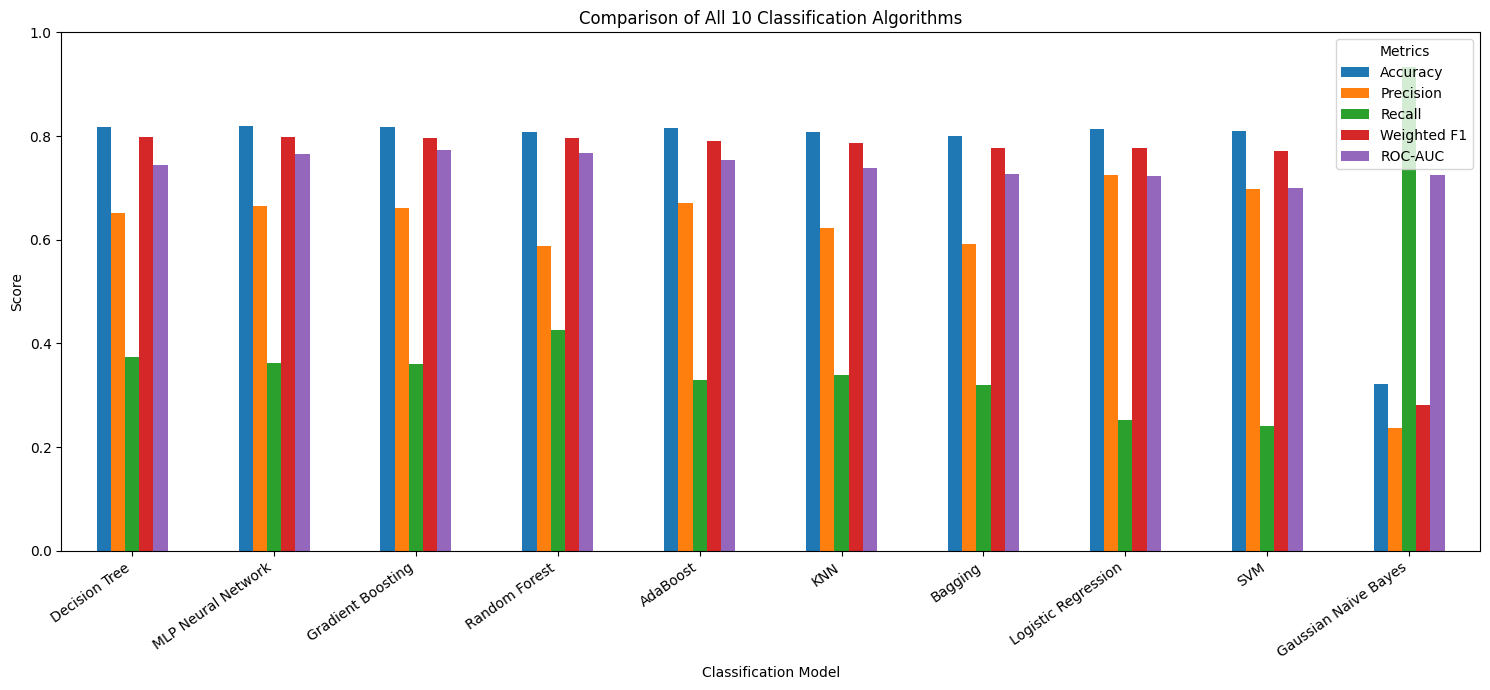

In [73]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "Weighted F1",
    "ROC-AUC"
]

final_comparison_df.set_index("Model")[
    metrics_to_plot
].plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Comparison of All 10 Classification Algorithms")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

### 14. Final Model Selection

The models are ranked by Weighted F1-score. Precision, Recall, ROC-AUC, and Accuracy are also considered to select a suitable classifier for credit card default prediction.

In [81]:
# 14. Final Model Selection

final_comparison_df = final_comparison_df.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

best_model_row = final_comparison_df.iloc[0]

print("Best Model:", best_model_row["Model"])

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "Weighted F1",
    "ROC-AUC"
]:
    print(f"{metric}: {best_model_row[metric]:.4f}")

Best Model: Decision Tree
Accuracy: 0.8173
Precision: 0.6518
Recall: 0.3741
Weighted F1: 0.7978
ROC-AUC: 0.7446


## 15. Conclusion

In this project, ten classification algorithms were implemented and evaluated for the classification task. The models were compared using Accuracy, Precision, Recall, Weighted F1-Score, and ROC-AUC.

Hyperparameter tuning was performed on selected models to improve their performance. Cross-validation was also used to evaluate model stability and compare performance across different data splits.

Based on the current test-set comparison, the **Decision Tree classifier** achieved an Accuracy of **0.8173** and a Weighted F1-Score of **0.7978**, making it the selected model according to Weighted F1-Score among the evaluated test results. Its ROC-AUC was **0.7446**.

The cross-validation results showed that Gradient Boosting and Random Forest also performed competitively. This highlights that the model with the highest cross-validation score may differ from the model with the highest test-set score.

Overall, this project demonstrates the importance of comparing multiple classification algorithms, tuning hyperparameters, and evaluating models using multiple performance metrics rather than relying on Accuracy alone.

In [75]:
print("Number of classification algorithms:", len(final_comparison_df))

print("\nMissing values in comparison table:")
print(final_comparison_df.isnull().sum())

print("\nFinal comparison table:")
display(final_comparison_df.round(4))

Number of classification algorithms: 10

Missing values in comparison table:
Model          0
Accuracy       0
Precision      0
Recall         0
Weighted F1    0
ROC-AUC        0
dtype: int64

Final comparison table:


,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Decision Tree,0.8173,0.6518,0.3741,0.7978,0.7446
1,MLP Neural Network,0.8185,0.6648,0.3620,0.7972,0.7655
2,Gradient Boosting,0.8176,0.6616,0.3597,0.7962,0.7723
3,Random Forest,0.8071,0.5884,0.4268,0.7954,0.7669
4,AdaBoost,0.8160,0.6713,0.3296,0.7907,0.7546
5,KNN,0.8083,0.6224,0.3394,0.7859,0.7389
6,Bagging,0.8006,0.5914,0.3198,0.7770,0.7274
7,Logistic Regression,0.8134,0.7251,0.2526,0.7763,0.7234
8,SVM,0.8089,0.6972,0.2413,0.7707,0.6989
9,Gaussian Naive Bayes,0.3220,0.2375,0.9336,0.2816,0.7245
